# Building a Moderate-Risk US Portfolio for a $1M Mandate
### Stocks + ETFs + Bonds | Mean-Variance Optimisation, Walk-Forward Backtest, Stress Tests & Monte Carlo

> **How to run:** click **Run All** (VS Code: *Exécuter tout*). The cells depend on each other, so running a single cell on a fresh kernel gives `NameError: name 'rets' is not defined`. If you want a one-command version, use `us_portfolio_analysis.py` instead.

**Mandate (the "client")**
- Budget: **$1,000,000**, long-only, no leverage, no derivatives
- Risk tolerance: **moderate**, which here means a target volatility of about 11% or less, no more than 65% in equities, at least 25% in bonds
- Horizon: 3+ years, annual rebalancing

**Questions this notebook answers**
1. What do 12 years of US market data say about each asset's return, risk and diversification value?
2. What is the best risk-adjusted mix of stocks, equity ETFs, bond ETFs and gold *inside the client's risk limits*?
3. Would this process have worked **out-of-sample** (walk-forward backtest with transaction costs), and how does it compare to a plain 60/40?
4. How bad can it get? (VaR/CVaR, historical stress tests, Monte Carlo)
5. What exactly do we buy on day one, in shares and dollars, and what would we tell the investment committee?

**Data:** Yahoo Finance via `yfinance` (adjusted prices, so dividends and splits are included).
*Educational project, not investment advice.*

## 1. Setup and client constraints

In [1]:
import os, warnings
try:
    import jinja2, yfinance  # jinja2 is needed for formatted tables, yfinance for the data download
except ImportError as e:
    raise ImportError(f"Missing package ({e.name}). Run:  %pip install jinja2 yfinance  then restart the kernel.") from e
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.optimize import minimize
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

# ---- Data / simulation settings
YEARS_HISTORY = 12
TODAY = pd.Timestamp.today().normalize()
START = TODAY - pd.DateOffset(years=YEARS_HISTORY)
TRADING_DAYS = 252
SEED = 42
rng = np.random.default_rng(SEED)

# ---- Mandate
BUDGET = 1_000_000
MAX_VOL = 0.11            # target annualised volatility ceiling
MIN_EQUITY, MAX_EQUITY = 0.35, 0.65     # stocks + equity ETFs
MIN_BONDS,  MAX_BONDS  = 0.25, 0.55
MAX_GOLD = 0.08
MAX_ALL_STOCKS = 0.25     # individual stocks combined
MAX_SINGLE_STOCK = 0.05
MAX_SINGLE_ETF = 0.20

# ---- Modelling choices
SHRINK_MU = 0.5           # pull each asset's return estimate halfway toward its asset-class mean
SHRINK_COV = 0.2          # shrink covariance toward a constant-correlation target
L2_PENALTY = 0.25         # diversification penalty in the optimiser
LOOKBACK_YEARS = 3        # training window in the walk-forward backtest
COST_BPS = 5              # transaction cost per unit of turnover

# ---- Plot style
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10, "axes.titleweight": "bold",
    "axes.titlesize": 12, "legend.frameon": False,
})
CLASS_COLORS = {"Stock": "#2a6fdb", "Equity ETF": "#14a3a3", "Bond ETF": "#e08a1e", "Commodity": "#8a6d3b"}

def savefig(name):
    plt.savefig(f"outputs/{name}.png", dpi=150, bbox_inches="tight")

## 2. Investment universe
26 liquid US-listed instruments across four buckets. The stocks are large caps spread across all major sectors; ETFs give broad equity, bond and gold exposure.

> **Survivorship caveat:** these stocks are today's large caps. Companies that fell out of the index are not here, so single-stock backtests flatter results. I come back to this in the memo.

In [2]:
UNIVERSE = pd.DataFrame([
    # ticker, name, class, sector
    ("AAPL", "Apple",                       "Stock", "Technology"),
    ("MSFT", "Microsoft",                   "Stock", "Technology"),
    ("NVDA", "NVIDIA",                      "Stock", "Technology"),
    ("JPM",  "JPMorgan Chase",              "Stock", "Financials"),
    ("V",    "Visa",                        "Stock", "Financials"),
    ("JNJ",  "Johnson & Johnson",           "Stock", "Healthcare"),
    ("UNH",  "UnitedHealth",                "Stock", "Healthcare"),
    ("PG",   "Procter & Gamble",            "Stock", "Consumer Staples"),
    ("KO",   "Coca-Cola",                   "Stock", "Consumer Staples"),
    ("XOM",  "Exxon Mobil",                 "Stock", "Energy"),
    ("HD",   "Home Depot",                  "Stock", "Consumer Discretionary"),
    ("NEE",  "NextEra Energy",              "Stock", "Utilities"),
    ("SPY",  "SPDR S&P 500",                "Equity ETF", "US Large Cap"),
    ("QQQ",  "Invesco Nasdaq-100",          "Equity ETF", "US Growth"),
    ("VIG",  "Vanguard Dividend Growth",    "Equity ETF", "US Dividend Growth"),
    ("IJR",  "iShares S&P SmallCap 600",    "Equity ETF", "US Small Cap"),
    ("USMV", "iShares Min Vol USA",         "Equity ETF", "US Low Volatility"),
    ("VNQ",  "Vanguard Real Estate",        "Equity ETF", "US REITs"),
    ("AGG",  "iShares Core US Aggregate",   "Bond ETF", "Core Bonds"),
    ("SHY",  "iShares 1-3Y Treasury",       "Bond ETF", "Short Treasuries"),
    ("IEF",  "iShares 7-10Y Treasury",      "Bond ETF", "Intermediate Treasuries"),
    ("TLT",  "iShares 20+Y Treasury",       "Bond ETF", "Long Treasuries"),
    ("LQD",  "iShares IG Corporate",        "Bond ETF", "Investment-Grade Credit"),
    ("HYG",  "iShares High Yield Corporate","Bond ETF", "High Yield"),
    ("TIP",  "iShares TIPS",                "Bond ETF", "Inflation-Linked"),
    ("GLD",  "SPDR Gold",                   "Commodity", "Gold"),
], columns=["ticker", "name", "class", "sector"]).set_index("ticker")

TICKERS = UNIVERSE.index.tolist()
def _m(c): return (UNIVERSE["class"] == c).values
IS_STOCK, IS_EQETF, IS_BOND, IS_GOLD = _m("Stock"), _m("Equity ETF"), _m("Bond ETF"), _m("Commodity")
IS_EQUITY = IS_STOCK | IS_EQETF
display(UNIVERSE["class"].value_counts().to_frame("count"))

,count
class,
Stock,12
Bond ETF,7
Equity ETF,6
Commodity,1


## 3. Download market data (Yahoo Finance API)
Prices are cached to `data/prices.csv`, so re-runs are instant. Set `REFRESH = True` to download again.

In [3]:
REFRESH = False
CACHE = "data/prices.csv"

def load_prices(tickers, start, refresh=False):
    if os.path.exists(CACHE) and not refresh:
        cached = pd.read_csv(CACHE, index_col=0, parse_dates=True)
        if set(tickers) <= set(cached.columns):
            print(f"Loaded cached prices from {CACHE}")
            return cached[tickers]
    import yfinance as yf
    print("Downloading from Yahoo Finance...")
    raw = yf.download(tickers, start=start, auto_adjust=True, progress=False)
    px = raw["Close"] if isinstance(raw.columns, pd.MultiIndex) else raw
    px = px[tickers]
    px.to_csv(CACHE)
    return px

px = load_prices(TICKERS, START, REFRESH)

# Data-quality checks
first_valid = px.apply(lambda s: s.first_valid_index())
late = first_valid[first_valid > px.index[0] + pd.Timedelta(days=30)]
if len(late):
    print("Assets with a shorter history (the common window will start later):")
    print(late.to_string())
px = px.ffill(limit=3).dropna()
assert px.shape[1] == len(TICKERS), "Some tickers returned no data"

rets = px.pct_change().dropna()
print(f"\n{px.shape[1]} assets | {len(px):,} trading days | {px.index[0].date()} to {px.index[-1].date()}")
print("Missing values after cleaning:", int(px.isna().sum().sum()))

# Risk-free rate: average 13-week T-bill yield over the window (fallback 4%)
RF = 0.04
try:
    import yfinance as yf
    irx = yf.download("^IRX", start=px.index[0], progress=False)["Close"].squeeze().dropna()
    candidate = float(irx.mean() / 100)
    if len(irx) > 100 and np.isfinite(candidate) and 0 <= candidate < 0.15:
        RF = candidate
        print(f"Risk-free rate (avg 13-week T-bill): {RF:.2%}")
    else:
        print(f"T-bill download returned no usable data, using RF = {RF:.2%}")
except Exception:
    print(f"Could not fetch T-bill yield, using RF = {RF:.2%}")
assert np.isfinite(RF)

Loaded cached prices from data/prices.csv

26 assets | 3,017 trading days | 2014-10-16 to 2026-10-15
Missing values after cleaning: 0
Risk-free rate (avg 13-week T-bill): 2.04%


## 4. Exploratory analysis: what does the data say?

In [4]:
def max_drawdown(r):
    wealth = (1 + r).cumprod()
    return (wealth / wealth.cummax() - 1).min()

def perf_table(r, rf=None):
    rf = RF if rf is None else rf
    r = r.to_frame("Portfolio") if isinstance(r, pd.Series) else r
    yrs = len(r) / TRADING_DAYS
    cagr = (1 + r).prod() ** (1 / yrs) - 1
    vol = r.std() * np.sqrt(TRADING_DAYS)
    sharpe = (r.mean() * TRADING_DAYS - rf) / vol
    mdd = r.apply(max_drawdown)
    return pd.DataFrame({"CAGR": cagr, "Volatility": vol, "Sharpe": sharpe,
                         "Max drawdown": mdd, "Calmar": cagr / mdd.abs()})

asset_stats = perf_table(rets).join(UNIVERSE[["name", "class"]])
fmt = {"CAGR": "{:.1%}", "Volatility": "{:.1%}", "Sharpe": "{:.2f}", "Max drawdown": "{:.1%}", "Calmar": "{:.2f}"}
display(asset_stats.sort_values("Sharpe", ascending=False)
        [["name", "class", "CAGR", "Volatility", "Sharpe", "Max drawdown", "Calmar"]]
        .style.format(fmt).background_gradient(subset=["Sharpe"], cmap="Greens"))

,name,class,CAGR,Volatility,Sharpe,Max drawdown,Calmar
NVDA,NVIDIA,Stock,68.7%,47.7%,1.29,-66.3%,1.04
MSFT,Microsoft,Stock,25.4%,27.4%,0.89,-37.1%,0.68
AAPL,Apple,Stock,26.2%,28.6%,0.89,-38.5%,0.68
QQQ,Invesco Nasdaq-100,Equity ETF,19.8%,21.8%,0.84,-35.1%,0.56
V,Visa,Stock,19.7%,24.2%,0.78,-36.4%,0.54
SPY,SPDR S&P 500,Equity ETF,14.5%,17.4%,0.75,-33.7%,0.43
JPM,JPMorgan Chase,Stock,19.4%,26.7%,0.72,-43.6%,0.44
VIG,Vanguard Dividend Growth,Equity ETF,12.6%,15.6%,0.71,-31.7%,0.40
USMV,iShares Min Vol USA,Equity ETF,10.9%,14.1%,0.66,-33.1%,0.33
UNH,UnitedHealth,Stock,15.8%,29.2%,0.58,-61.4%,0.26


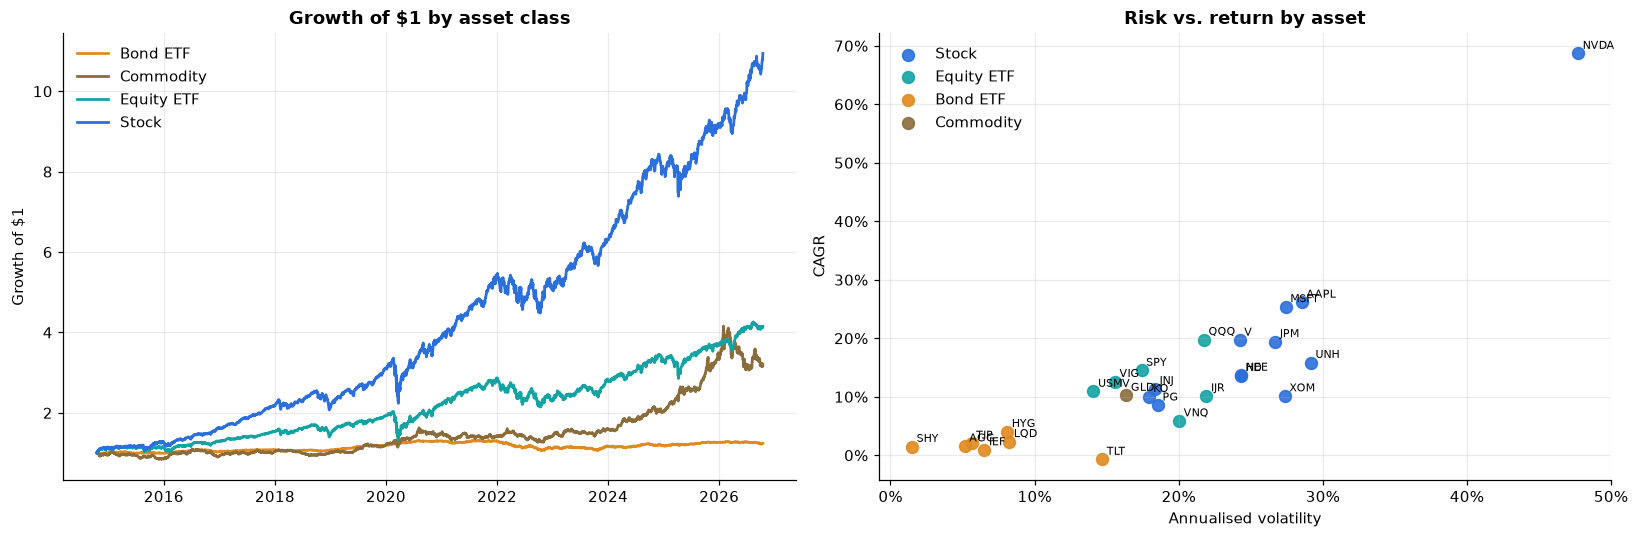

In [5]:
# Growth of $1 by asset class (equal-weighted inside each class)
class_ret = rets.T.groupby(UNIVERSE["class"]).mean().T
growth = (1 + class_ret).cumprod()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for c in growth.columns:
    axes[0].plot(growth.index, growth[c], label=c, color=CLASS_COLORS[c], lw=1.8)
axes[0].set_title("Growth of $1 by asset class")
axes[0].set_ylabel("Growth of $1"); axes[0].legend()

for c, col in CLASS_COLORS.items():
    sub = asset_stats[asset_stats["class"] == c]
    axes[1].scatter(sub["Volatility"], sub["CAGR"], s=60, color=col, label=c, alpha=0.9)
    for t, row in sub.iterrows():
        axes[1].annotate(t, (row["Volatility"], row["CAGR"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_xlabel("Annualised volatility"); axes[1].set_ylabel("CAGR"); axes[1].set_title("Risk vs. return by asset")
axes[1].legend()
plt.tight_layout(); savefig("01_asset_class_growth_and_risk_return"); plt.show()

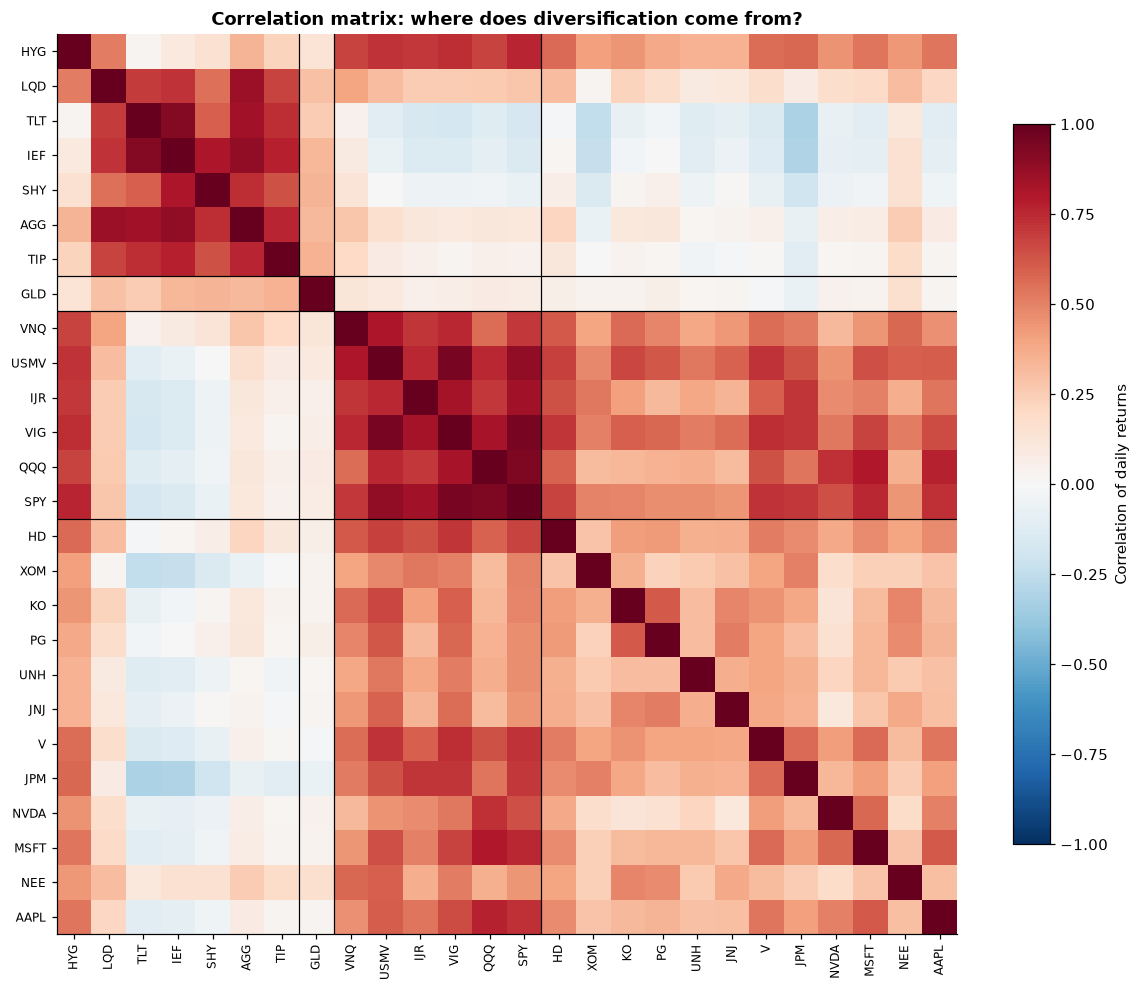

{'stock-stock': 0.37, 'stock-bond': 0.08, 'stock-gold': 0.03}


In [6]:
# Correlation matrix, ordered by asset class
order = UNIVERSE.sort_values("class").index
corr = rets[order].corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(order))); ax.set_yticks(range(len(order)))
ax.set_xticklabels(order, rotation=90, fontsize=8); ax.set_yticklabels(order, fontsize=8)
ax.grid(False)
bounds = np.cumsum(UNIVERSE.loc[order, "class"].value_counts(sort=False).reindex(UNIVERSE.loc[order, "class"].unique()).values)[:-1] - 0.5
for b in bounds:
    ax.axhline(b, color="black", lw=0.8); ax.axvline(b, color="black", lw=0.8)
plt.colorbar(im, shrink=0.8, label="Correlation of daily returns")
ax.set_title("Correlation matrix: where does diversification come from?")
plt.tight_layout(); savefig("02_correlation_matrix"); plt.show()

avg = {"stock-stock": corr.loc[order[UNIVERSE.loc[order, 'class'] == 'Stock'], order[UNIVERSE.loc[order, 'class'] == 'Stock']].values[np.triu_indices(IS_STOCK.sum(), 1)].mean(),
       "stock-bond": corr.loc[order[UNIVERSE.loc[order, 'class'] == 'Stock'], order[UNIVERSE.loc[order, 'class'] == 'Bond ETF']].values.mean(),
       "stock-gold": corr.loc[order[UNIVERSE.loc[order, 'class'] == 'Stock'], "GLD"].mean()}
print({k: round(float(v), 2) for k, v in avg.items()})

## 5. Estimating expected returns and risk
Raw historical means are noisy, and optimisers love noise ("error maximisers"). Two standard guards:

- **Return shrinkage:** each asset's expected return is a 50/50 blend of its own history and its asset-class average. This keeps the equity/bond risk premium but stops one lucky stock from dominating.
- **Covariance shrinkage:** the sample covariance is blended 80/20 with a constant-correlation matrix, which is more stable out-of-sample.

In [7]:
def shrink_cov(R, delta=SHRINK_COV):
    S = R.cov().values * TRADING_DAYS
    sd = np.sqrt(np.diag(S))
    C = S / np.outer(sd, sd)
    n = len(sd)
    rbar = (C.sum() - n) / (n * (n - 1))
    F = rbar * np.outer(sd, sd)
    np.fill_diagonal(F, sd ** 2)
    return pd.DataFrame((1 - delta) * S + delta * F, index=R.columns, columns=R.columns)

def estimate(R):
    mu_hist = R.mean() * TRADING_DAYS
    cls_mean = mu_hist.groupby(UNIVERSE["class"]).transform("mean")
    mu = (1 - SHRINK_MU) * mu_hist + SHRINK_MU * cls_mean
    return mu, shrink_cov(R)

mu, cov = estimate(rets)
display(pd.DataFrame({"Historical": rets.mean() * TRADING_DAYS, "Shrunk (used)": mu}).join(UNIVERSE["class"])
        .sort_values("Shrunk (used)", ascending=False).head(10).style.format({"Historical": "{:.1%}", "Shrunk (used)": "{:.1%}"}))

,Historical,Shrunk (used),class
NVDA,63.6%,42.5%,Stock
AAPL,27.3%,24.4%,Stock
MSFT,26.4%,23.9%,Stock
JPM,21.3%,21.4%,Stock
V,20.9%,21.2%,Stock
UNH,19.1%,20.2%,Stock
NEE,15.8%,18.6%,Stock
HD,15.8%,18.6%,Stock
XOM,13.4%,17.4%,Stock
JNJ,12.5%,17.0%,Stock


## 6. Portfolio optimisation under the client's mandate
**Objective:** maximise the Sharpe ratio, with a small L2 penalty that discourages concentrated corner solutions.

**Constraints:** fully invested, long-only, a volatility cap of 11%, asset-class bands (equity 35-65%, bonds 25-55%, gold ≤ 8%, individual stocks ≤ 25% combined), and position limits (stock ≤ 5%, ETF ≤ 20%).

In [8]:
BOUNDS = [(0, MAX_SINGLE_STOCK) if s else (0, MAX_SINGLE_ETF) for s in IS_STOCK]
X0 = np.where(IS_STOCK, 0.20 / IS_STOCK.sum(),
     np.where(IS_EQETF, 0.35 / IS_EQETF.sum(),
     np.where(IS_BOND,  0.40 / IS_BOND.sum(), 0.05 / IS_GOLD.sum())))

def make_constraints(S, vol_cap=None):
    cons = [
        {"type": "eq",   "fun": lambda w: w.sum() - 1.0},
        {"type": "ineq", "fun": lambda w: MAX_EQUITY - w[IS_EQUITY].sum()},
        {"type": "ineq", "fun": lambda w: w[IS_EQUITY].sum() - MIN_EQUITY},
        {"type": "ineq", "fun": lambda w: w[IS_BOND].sum() - MIN_BONDS},
        {"type": "ineq", "fun": lambda w: MAX_BONDS - w[IS_BOND].sum()},
        {"type": "ineq", "fun": lambda w: MAX_GOLD - w[IS_GOLD].sum()},
        {"type": "ineq", "fun": lambda w: MAX_ALL_STOCKS - w[IS_STOCK].sum()},
    ]
    if vol_cap is not None:
        cons.append({"type": "ineq", "fun": lambda w: vol_cap ** 2 - w @ S @ w})
    return cons

def optimise(mu, cov, kind="sharpe", vol_cap=None, target_ret=None, x0=None):
    m, S = mu.values, cov.values
    if kind == "sharpe":
        f = lambda w: -(w @ m - RF) / np.sqrt(w @ S @ w) + L2_PENALTY * np.sum(w ** 2)
    elif kind == "minvar":
        f = lambda w: 100 * (w @ S @ w)
    elif kind == "maxret":
        f = lambda w: -(w @ m)
    cons = make_constraints(S, vol_cap)
    if target_ret is not None:
        cons.append({"type": "ineq", "fun": lambda w: w @ m - target_ret})
    res = minimize(f, X0 if x0 is None else x0, method="SLSQP", bounds=BOUNDS,
                   constraints=cons, options={"maxiter": 600, "ftol": 1e-10})
    w = pd.Series(np.clip(res.x, 0, None), index=mu.index)
    w[w < 0.0025] = 0.0          # drop dust positions
    return w / w.sum(), res.success

def port_stats(w, mu, cov):
    r = float(w @ mu); v = float(np.sqrt(w @ cov @ w))
    return r, v, (r - RF) / v

w_final, ok = optimise(mu, cov, "sharpe", vol_cap=MAX_VOL)
w_minvar, _ = optimise(mu, cov, "minvar")
print("Optimiser converged:", ok)
for name, w in {"Max-Sharpe (moderate mandate)": w_final, "Min-variance (same mandate)": w_minvar}.items():
    r, v, s = port_stats(w, mu, cov)
    print(f"{name:32s} exp.return {r:6.2%} | vol {v:6.2%} | Sharpe {s:4.2f} | holdings {int((w > 0).sum())}")

Optimiser converged: True
Max-Sharpe (moderate mandate)    exp.return 10.01% | vol  7.57% | Sharpe 1.05 | holdings 17
Min-variance (same mandate)      exp.return  7.06% | vol  5.98% | Sharpe 0.84 | holdings 11


In [9]:
# Did the optimiser respect the mandate?
def check_mandate(w, cov, tol=2e-3):
    vol = float(np.sqrt(w @ cov @ w))
    rows = [
        ("Fully invested (sum = 100%)",            w.sum(),                  abs(w.sum() - 1) < tol),
        ("Equity weight within 35-65%",            w[IS_EQUITY].sum(),       MIN_EQUITY - tol <= w[IS_EQUITY].sum() <= MAX_EQUITY + tol),
        ("Bond weight within 25-55%",              w[IS_BOND].sum(),         MIN_BONDS - tol <= w[IS_BOND].sum() <= MAX_BONDS + tol),
        ("Gold <= 8%",                             w[IS_GOLD].sum(),         w[IS_GOLD].sum() <= MAX_GOLD + tol),
        ("Individual stocks <= 25% combined",      w[IS_STOCK].sum(),        w[IS_STOCK].sum() <= MAX_ALL_STOCKS + tol),
        ("Largest single stock <= 5%",             w[IS_STOCK].max(),        w[IS_STOCK].max() <= MAX_SINGLE_STOCK + tol),
        ("Largest single ETF <= 20%",              w[~IS_STOCK].max(),       w[~IS_STOCK].max() <= MAX_SINGLE_ETF + tol),
        ("No short positions",                     w.min(),                  w.min() >= -tol),
        ("Volatility <= 11% (model)",              vol,                      vol <= MAX_VOL + tol),
    ]
    return pd.DataFrame(rows, columns=["Check", "Value", "Pass"]).set_index("Check")

chk = check_mandate(w_final, cov)
display(chk.style.format({"Value": "{:.2%}"}))
assert chk["Pass"].all(), "Mandate violated, review constraints"

,Value,Pass
Check,,
Fully invested (sum = 100%),100.00%,True
Equity weight within 35-65%,43.08%,True
Bond weight within 25-55%,48.91%,True
Gold <= 8%,8.02%,True
Individual stocks <= 25% combined,24.84%,True
Largest single stock <= 5%,5.01%,True
Largest single ETF <= 20%,20.04%,True
No short positions,0.00%,True
Volatility <= 11% (model),7.57%,True


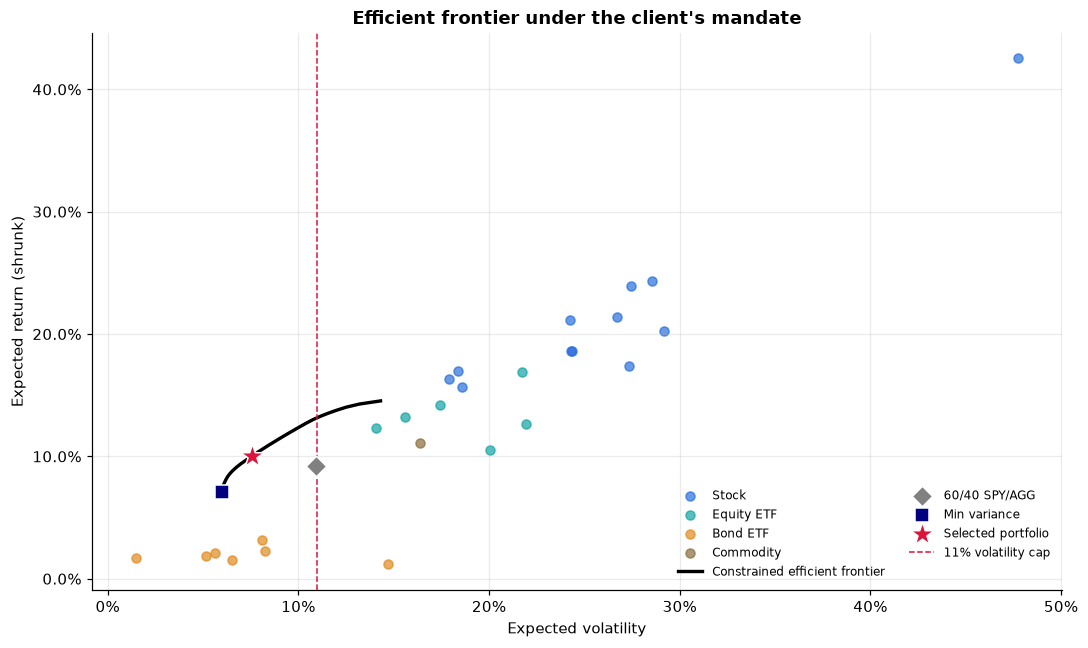

In [10]:
# Constrained efficient frontier
w0, _ = optimise(mu, cov, "minvar")
w_max, _ = optimise(mu, cov, "maxret")
r_lo, r_hi = float(w0 @ mu), float(w_max @ mu)
frontier, x_prev = [], X0
for tr in np.linspace(r_lo, r_hi * 0.999, 30):
    w, success = optimise(mu, cov, "minvar", target_ret=tr, x0=x_prev)
    if success:
        r, v, _ = port_stats(w, mu, cov); frontier.append((v, r)); x_prev = w.values
frontier = np.array(frontier)

fig, ax = plt.subplots(figsize=(10, 6))
for c, col in CLASS_COLORS.items():
    idx = UNIVERSE["class"] == c
    ax.scatter(np.sqrt(np.diag(cov))[idx.values], mu[idx], s=35, color=col, alpha=0.7, label=c)
ax.plot(frontier[:, 0], frontier[:, 1], color="black", lw=2.2, label="Constrained efficient frontier")
bench = pd.Series({"SPY": 1.0}).reindex(TICKERS).fillna(0)
b6040 = pd.Series({"SPY": 0.6, "AGG": 0.4}).reindex(TICKERS).fillna(0)
for lab, w, mk, col in [("60/40 SPY/AGG", b6040, "D", "gray"), ("Min variance", w_minvar, "s", "navy"), ("Selected portfolio", w_final, "*", "crimson")]:
    r, v, _ = port_stats(w, mu, cov)
    ax.scatter(v, r, marker=mk, s=260 if mk == "*" else 90, color=col, edgecolor="white", zorder=5, label=lab)
ax.axvline(MAX_VOL, color="crimson", ls="--", lw=1, label="11% volatility cap")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Expected volatility"); ax.set_ylabel("Expected return (shrunk)")
ax.set_title("Efficient frontier under the client's mandate"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); savefig("03_efficient_frontier"); plt.show()

## 7. Walk-forward backtest (the honest test)
In-sample optimisation always looks great. The real question is whether the *process* works on data it has not seen.

Each January the strategy:
1. looks only at the **previous 3 years**,
2. re-estimates returns and covariance (with shrinkage),
3. re-optimises under the same mandate, and
4. holds for the year, paying **5 bps per unit of turnover**.

It is compared against 60/40 (SPY/AGG), the S&P 500 alone and an equal-weight basket, all rebalanced on the same dates with the same costs.

In [11]:
def run_strategy(R, schedule, cost_bps=COST_BPS):
    dates = sorted(schedule); out = []; w_drift = None
    for i, d in enumerate(dates):
        end = dates[i + 1] if i + 1 < len(dates) else None
        period = R.loc[d:] if end is None else R.loc[d:end - pd.Timedelta(days=1)]
        w = schedule[d].reindex(R.columns).fillna(0).values
        growth = (1 + period).cumprod()
        value = growth.values @ w
        pret = pd.Series(value, index=period.index).pct_change()
        pret.iloc[0] = value[0] - 1
        turnover = 1.0 if w_drift is None else np.abs(w - w_drift).sum()
        pret.iloc[0] -= turnover * cost_bps / 1e4
        w_drift = growth.iloc[-1].values * w; w_drift = w_drift / w_drift.sum()
        out.append(pret)
    return pd.concat(out)

years = sorted(set(rets.index.year))
reb_dates = [rets.index[rets.index.year == y][0] for y in years]
reb_dates = [d for d in reb_dates if d - pd.DateOffset(years=LOOKBACK_YEARS) >= rets.index[0]]

opt_schedule, fallbacks = {}, 0
prev = pd.Series(X0, index=TICKERS)
for d in reb_dates:
    train = rets.loc[d - pd.DateOffset(years=LOOKBACK_YEARS): d - pd.Timedelta(days=1)]
    m_, c_ = estimate(train)
    w, success = optimise(m_, c_, "sharpe", vol_cap=MAX_VOL)
    if not success:
        w, fallbacks = prev, fallbacks + 1
    opt_schedule[d] = w; prev = w
print(f"{len(reb_dates)} rebalances from {reb_dates[0].date()} | optimiser fallbacks: {fallbacks}")

STRAT, B6040, BSPY, BEW = "Optimised (walk-forward)", "60/40 (SPY/AGG)", "S&P 500 (SPY)", "Equal-weight (26 assets)"
const = lambda w: {d: w for d in reb_dates}
bt = pd.DataFrame({
    STRAT: run_strategy(rets, opt_schedule),
    B6040: run_strategy(rets, const(b6040)),
    BSPY:  run_strategy(rets, const(bench)),
    BEW:   run_strategy(rets, const(pd.Series(1 / len(TICKERS), index=TICKERS))),
})
bt_stats = perf_table(bt)
display(bt_stats.style.format(fmt).background_gradient(subset=["Sharpe"], cmap="Greens"))

9 rebalances from 2018-01-02 | optimiser fallbacks: 0


,CAGR,Volatility,Sharpe,Max drawdown,Calmar
Optimised (walk-forward),9.2%,8.4%,0.85,-17.9%,0.51
60/40 (SPY/AGG),9.5%,11.7%,0.66,-21.0%,0.45
S&P 500 (SPY),14.6%,19.0%,0.71,-33.7%,0.43
Equal-weight (26 assets),13.6%,12.8%,0.90,-24.3%,0.56


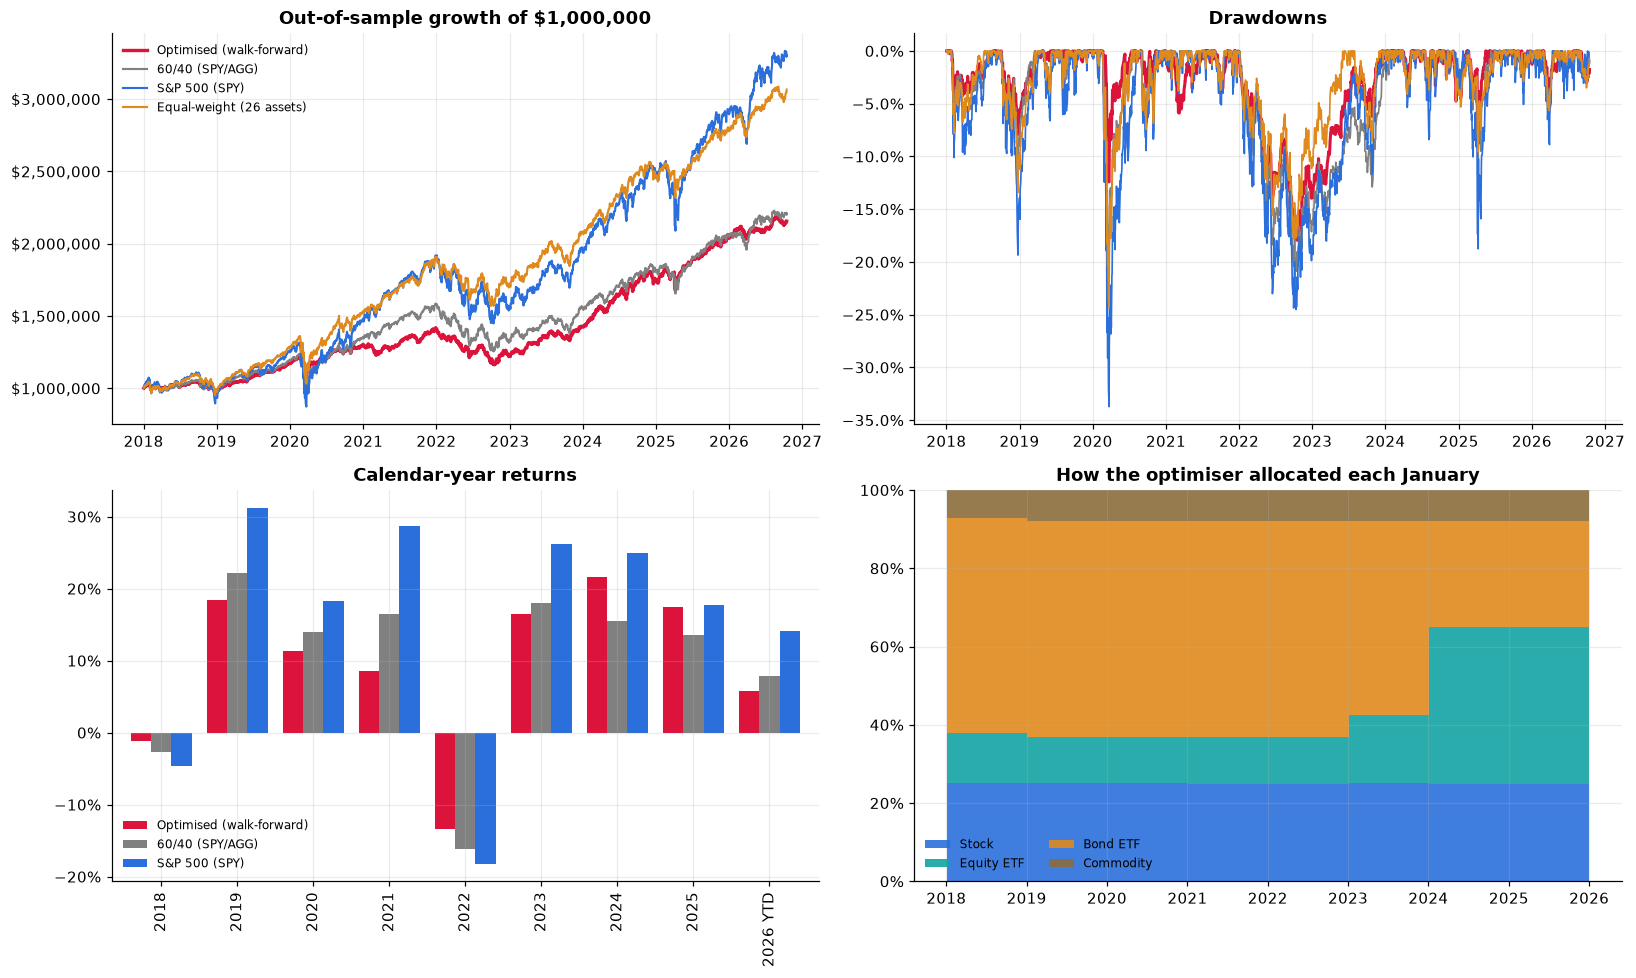

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
pal = {STRAT: "crimson", B6040: "gray", BSPY: "#2a6fdb", BEW: "#e08a1e"}
wealth = BUDGET * (1 + bt).cumprod()
for c in bt.columns:
    axes[0, 0].plot(wealth.index, wealth[c], label=c, color=pal[c], lw=2.2 if c == STRAT else 1.4)
axes[0, 0].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}")); axes[0, 0].legend(fontsize=8)
axes[0, 0].set_title("Out-of-sample growth of $1,000,000")

dd = wealth / wealth.cummax() - 1
for c in bt.columns:
    axes[0, 1].plot(dd.index, dd[c], color=pal[c], lw=2 if c == STRAT else 1.1, label=c)
axes[0, 1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[0, 1].set_title("Drawdowns")

cal = bt.groupby(bt.index.year).apply(lambda r: (1 + r).prod() - 1)
if bt.index[-1] < pd.Timestamp(bt.index[-1].year, 12, 15):
    cal.index = [f"{y} YTD" if y == bt.index[-1].year else str(y) for y in cal.index]
cal[[STRAT, B6040, BSPY]].plot.bar(ax=axes[1, 0], color=[pal[STRAT], pal[B6040], pal[BSPY]], width=0.8)
axes[1, 0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1, 0].set_title("Calendar-year returns"); axes[1, 0].set_xlabel("")
axes[1, 0].legend(fontsize=8)

wts = pd.DataFrame(opt_schedule).T
wts_cls = wts.T.groupby(UNIVERSE["class"]).sum().T[list(CLASS_COLORS)]
axes[1, 1].stackplot(wts_cls.index, wts_cls.T.values, labels=wts_cls.columns, colors=[CLASS_COLORS[c] for c in wts_cls.columns], alpha=0.9, step="post")
axes[1, 1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1, 1].set_ylim(0, 1)
axes[1, 1].set_title("How the optimiser allocated each January"); axes[1, 1].legend(loc="lower left", fontsize=8, ncol=2)
plt.tight_layout(); savefig("04_walk_forward_backtest"); plt.show()

## 8. Final recommended portfolio
Optimised on the full 12-year sample (the same procedure the backtest used each year).

,name,class,sector,weight,target_$,last_price,shares,invested_$
SHY,iShares 1-3Y Treasury,Bond ETF,Short Treasuries,20.0%,"$200,424",$81.29,2465,"$200,380"
TIP,iShares TIPS,Bond ETF,Inflation-Linked,13.3%,"$133,201",$105.29,1265,"$133,192"
USMV,iShares Min Vol USA,Equity ETF,US Low Volatility,11.6%,"$115,726",$101.58,1139,"$115,700"
IEF,iShares 7-10Y Treasury,Bond ETF,Intermediate Treasuries,10.3%,"$103,290",$90.35,1143,"$103,270"
GLD,SPDR Gold,Commodity,Gold,8.0%,"$80,169",$382.71,209,"$79,986"
VIG,Vanguard Dividend Growth,Equity ETF,US Dividend Growth,5.8%,"$57,841",$242.05,238,"$57,608"
AGG,iShares Core US Aggregate,Bond ETF,Core Bonds,5.2%,"$52,149",$95.41,546,"$52,094"
NVDA,NVIDIA,Stock,Technology,5.0%,"$50,106",$217.23,230,"$49,963"
KO,Coca-Cola,Stock,Consumer Staples,5.0%,"$50,106",$92.00,544,"$50,048"
JNJ,Johnson & Johnson,Stock,Healthcare,5.0%,"$50,106",$253.28,197,"$49,896"


Residual cash from whole-share rounding: $2,226 (0.22%)


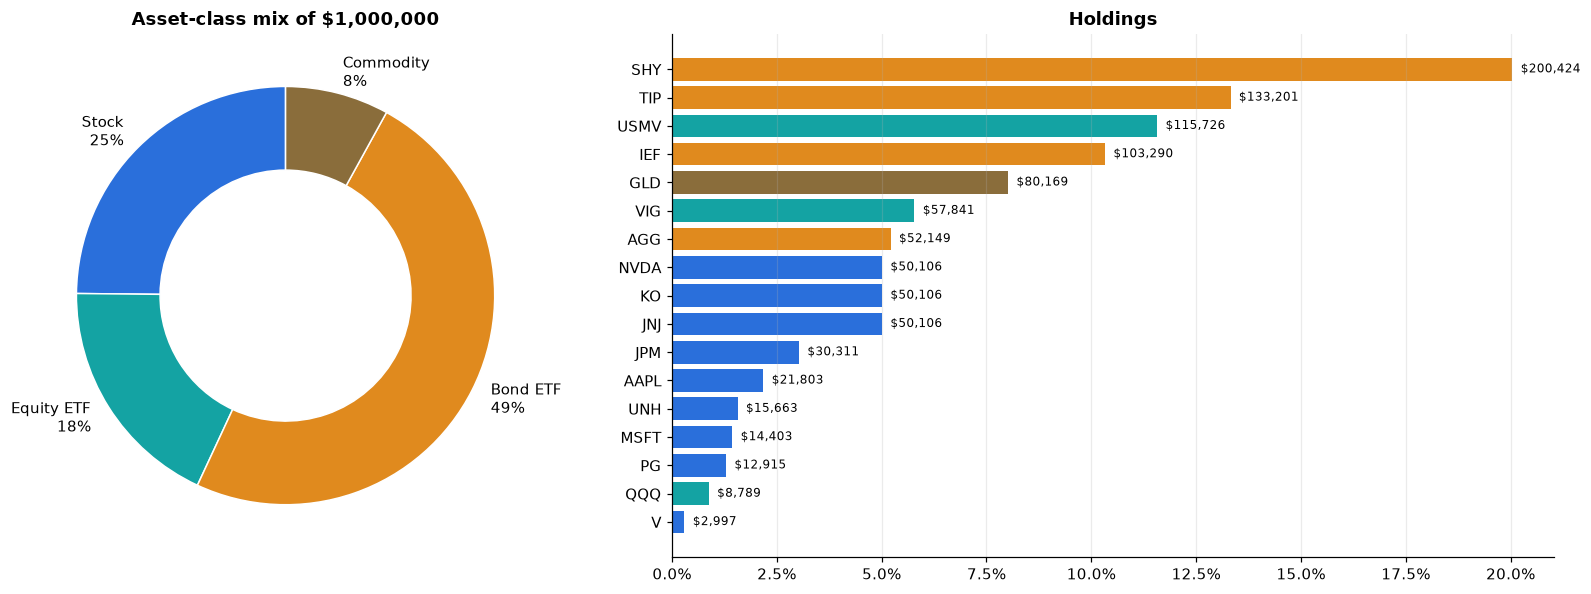

In [13]:
alloc = pd.DataFrame({"weight": w_final}).join(UNIVERSE)
alloc = alloc[alloc["weight"] > 0].sort_values("weight", ascending=False)
alloc["last_price"] = px.iloc[-1].reindex(alloc.index)
alloc["target_$"] = alloc["weight"] * BUDGET
alloc["shares"] = np.floor(alloc["target_$"] / alloc["last_price"]).astype(int)
alloc["invested_$"] = alloc["shares"] * alloc["last_price"]
alloc["actual_weight"] = alloc["invested_$"] / BUDGET
cash = BUDGET - alloc["invested_$"].sum()

display(alloc[["name", "class", "sector", "weight", "target_$", "last_price", "shares", "invested_$"]].style.format(
    {"weight": "{:.1%}", "target_$": "${:,.0f}", "last_price": "${:,.2f}", "invested_$": "${:,.0f}"}))
print(f"Residual cash from whole-share rounding: ${cash:,.0f} ({cash / BUDGET:.2%})")
alloc.to_csv("outputs/final_allocation.csv")

cls_w = w_final.groupby(UNIVERSE["class"]).sum().reindex(list(CLASS_COLORS)).fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.5]})
nz = cls_w[cls_w > 0]
axes[0].pie(nz, labels=[f"{k}\n{v:.0%}" for k, v in nz.items()], colors=[CLASS_COLORS[k] for k in nz.index],
            startangle=90, wedgeprops={"width": 0.4, "edgecolor": "white"})
axes[0].set_title(f"Asset-class mix of ${BUDGET:,.0f}")
a = alloc.iloc[::-1]
axes[1].barh(a.index, a["weight"], color=[CLASS_COLORS[c] for c in a["class"]])
for i, (t, row) in enumerate(a.iterrows()):
    axes[1].text(row["weight"] + 0.002, i, f"${row['target_$']:,.0f}", va="center", fontsize=8)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1].set_title("Holdings"); axes[1].grid(axis="y", alpha=0)
plt.tight_layout(); savefig("05_final_allocation"); plt.show()

## 9. Risk analysis for the investment committee
Risk is not just volatility. Here is what a PM actually asks: *how much could we lose in a bad month, which positions drive the risk, and what happened in past crises?*

,% of portfolio,$ on $1M
1-day VaR 95%,0.66%,"$6,559"
1-day CVaR 95%,1.07%,"$10,661"
1-day VaR 99%,1.19%,"$11,927"
1-month VaR 95%,2.46%,"$24,577"
1-month CVaR 95%,4.26%,"$42,564"
Worst month,13.84%,"$138,406"


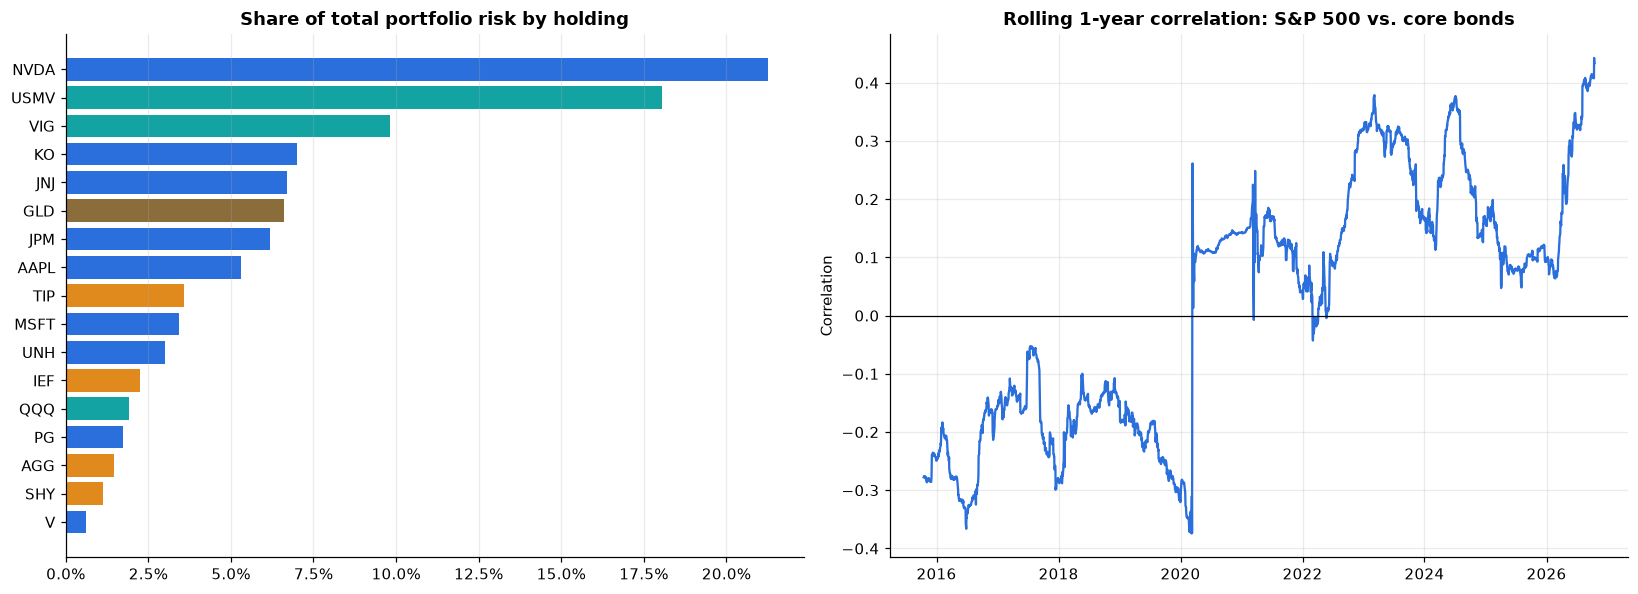

SPY/AGG correlation: -0.01 before 2022 vs 0.32 during 2022
Equity share of portfolio weight: 43% | equity share of risk: 85%


In [14]:
port = rets @ w_final                      # daily-rebalanced history of the recommended portfolio
spy, p6040 = rets["SPY"], 0.6 * rets["SPY"] + 0.4 * rets["AGG"]

# --- Value-at-Risk / Expected Shortfall (historical simulation)
roll21 = np.expm1(np.log1p(port).rolling(21).sum()).dropna()
risk = {
    "1-day VaR 95%":       -np.percentile(port, 5),
    "1-day CVaR 95%":      -port[port <= np.percentile(port, 5)].mean(),
    "1-day VaR 99%":       -np.percentile(port, 1),
    "1-month VaR 95%":     -np.percentile(roll21, 5),
    "1-month CVaR 95%":    -roll21[roll21 <= np.percentile(roll21, 5)].mean(),
    "Worst month":         -roll21.min(),
}
risk_df = pd.DataFrame({"% of portfolio": risk, "$ on $1M": {k: v * BUDGET for k, v in risk.items()}})
display(risk_df.style.format({"% of portfolio": "{:.2%}", "$ on $1M": "${:,.0f}"}))

# --- Risk contribution
sigma = np.sqrt(w_final @ cov @ w_final)
rc = (w_final * (cov @ w_final)) / sigma ** 2
rc = rc[w_final > 0].sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh(rc.index, rc.values, color=[CLASS_COLORS[UNIVERSE.loc[t, "class"]] for t in rc.index])
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[0].grid(axis="y", alpha=0)
axes[0].set_title("Share of total portfolio risk by holding")

# --- Rolling stock/bond correlation: does the hedge hold up?
roll_corr = rets["SPY"].rolling(252).corr(rets["AGG"])
axes[1].plot(roll_corr.index, roll_corr, color="#2a6fdb")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Rolling 1-year correlation: S&P 500 vs. core bonds"); axes[1].set_ylabel("Correlation")
plt.tight_layout(); savefig("06_risk_contribution_and_stock_bond_correlation"); plt.show()
corr_2022 = rets.loc["2022", ["SPY", "AGG"]].corr().iloc[0, 1]
corr_pre = rets.loc[:"2021", ["SPY", "AGG"]].corr().iloc[0, 1]
print(f"SPY/AGG correlation: {corr_pre:.2f} before 2022 vs {corr_2022:.2f} during 2022")
print("Equity share of portfolio weight: {:.0%} | equity share of risk: {:.0%}".format(
    w_final[IS_EQUITY].sum(), rc[[t for t in rc.index if UNIVERSE.loc[t, 'class'] in ('Stock', 'Equity ETF')]].sum()))

,Recommended,60/40,S&P 500,Loss on $1M
Scenario,,,,
Q4 2018 sell-off,-7.4%,-11.2%,-18.9%,"-$74,147"
COVID crash,-13.7%,-21.5%,-33.4%,"-$136,653"
2022 inflation / rate shock,-15.3%,-20.1%,-24.1%,"-$153,206"


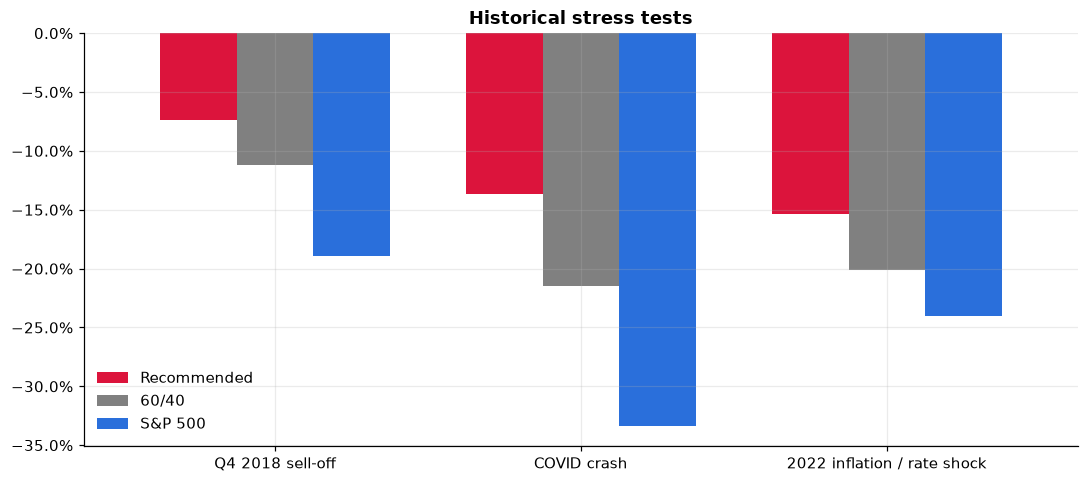

In [15]:
# --- Historical stress tests (cumulative return over each episode)
scenarios = {
    "Q4 2018 sell-off":           ("2018-10-01", "2018-12-24"),
    "COVID crash":                ("2020-02-19", "2020-03-23"),
    "2022 inflation / rate shock": ("2022-01-03", "2022-10-12"),
}
rows = []
for name, (a, b) in scenarios.items():
    if pd.Timestamp(a) < rets.index[0] or pd.Timestamp(b) > rets.index[-1]:
        continue
    f = lambda s: (1 + s.loc[a:b]).prod() - 1
    rows.append({"Scenario": name, "Recommended": f(port), "60/40": f(p6040), "S&P 500": f(spy),
                 "Loss on $1M": f(port) * BUDGET})
stress = pd.DataFrame(rows).set_index("Scenario")
display(stress.style.format({"Recommended": "{:.1%}", "60/40": "{:.1%}", "S&P 500": "{:.1%}", "Loss on $1M": lambda v: f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}"}))

ax = stress[["Recommended", "60/40", "S&P 500"]].plot.bar(figsize=(10, 4.5), color=["crimson", "gray", "#2a6fdb"], width=0.75)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_title("Historical stress tests"); ax.set_xlabel("")
plt.xticks(rotation=0); plt.tight_layout(); savefig("07_stress_tests"); plt.show()

## 10. Monte Carlo: the range of outcomes over the next 3 years
10,000 simulated paths built by **block-bootstrapping** the portfolio's own daily returns (21-day blocks, which preserves volatility clustering and short-term momentum).

Because the sample (2014 onward) was a strong bull market, I subtract a **2 percentage-point annual haircut** from the drift so the simulation does not simply extrapolate the past. Change `HAIRCUT` to see the sensitivity.

,Value
Median ending value,"$1,278,658"
5th percentile (bad case),"$1,037,507"
95th percentile (good case),"$1,536,826"
Probability of losing money,2.7%
Probability of lagging 2.5% inflation,8.5%
Probability of a >15% drawdown at some point,8.8%


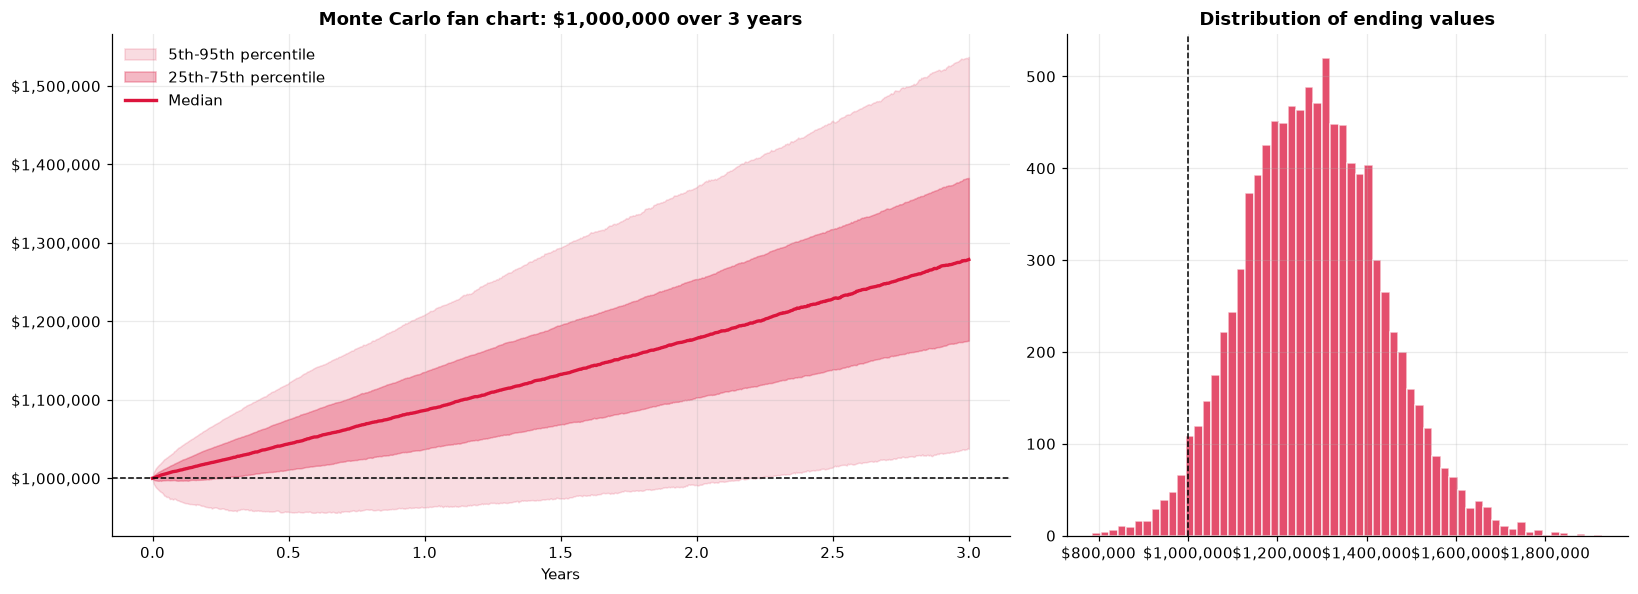

In [16]:
HORIZON_YEARS, N_PATHS, BLOCK, HAIRCUT, INFLATION = 3, 10_000, 21, 0.02, 0.025

def bootstrap_paths(daily, horizon, n_paths, block=BLOCK, haircut=HAIRCUT):
    T = len(daily); n_blocks = int(np.ceil(horizon / block))
    starts = rng.integers(0, T - block, size=(n_paths, n_blocks))
    idx = (starts[:, :, None] + np.arange(block)[None, None, :]).reshape(n_paths, -1)[:, :horizon]
    r = daily.values[idx] - haircut / TRADING_DAYS
    return np.cumprod(1 + r, axis=1)

H = HORIZON_YEARS * TRADING_DAYS
paths = BUDGET * np.hstack([np.ones((N_PATHS, 1)), bootstrap_paths(port, H, N_PATHS)])
terminal = paths[:, -1]
mdd = (paths / np.maximum.accumulate(paths, axis=1) - 1).min(axis=1)
pct = np.percentile(paths, [5, 25, 50, 75, 95], axis=0)
t_axis = np.arange(H + 1) / TRADING_DAYS

mc = pd.Series({
    "Median ending value":        np.median(terminal),
    "5th percentile (bad case)":  np.percentile(terminal, 5),
    "95th percentile (good case)": np.percentile(terminal, 95),
    "Probability of losing money": (terminal < BUDGET).mean(),
    f"Probability of lagging {INFLATION:.1%} inflation": (terminal < BUDGET * (1 + INFLATION) ** HORIZON_YEARS).mean(),
    "Probability of a >15% drawdown at some point": (mdd < -0.15).mean(),
})
display(mc.to_frame("Value").style.format(lambda v: f"${v:,.0f}" if v > 1 else f"{v:.1%}"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].fill_between(t_axis, pct[0], pct[4], color="crimson", alpha=0.15, label="5th-95th percentile")
axes[0].fill_between(t_axis, pct[1], pct[3], color="crimson", alpha=0.30, label="25th-75th percentile")
axes[0].plot(t_axis, pct[2], color="crimson", lw=2.2, label="Median")
axes[0].axhline(BUDGET, color="black", ls="--", lw=1)
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}")); axes[0].set_xlabel("Years"); axes[0].legend()
axes[0].set_title(f"Monte Carlo fan chart: ${BUDGET:,.0f} over {HORIZON_YEARS} years")
axes[1].hist(terminal, bins=60, color="crimson", alpha=0.75, edgecolor="white")
axes[1].axvline(BUDGET, color="black", ls="--", lw=1)
axes[1].xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}")); axes[1].set_title("Distribution of ending values")
plt.tight_layout(); savefig("08_monte_carlo"); plt.show()

## 11. Investment committee memo
The text below is generated from the results above, so the numbers always match the analysis.

In [17]:
r_exp, v_exp, s_exp = port_stats(w_final, mu, cov)
ps = perf_table(port).iloc[0]
s_strat, s_6040 = bt_stats.loc[STRAT], bt_stats.loc[B6040]
top5 = w_final.sort_values(ascending=False).head(5)
beat_sharpe = s_strat["Sharpe"] > s_6040["Sharpe"]
beat_dd = s_strat["Max drawdown"] > s_6040["Max drawdown"]
worst_name = stress["Recommended"].idxmin() if len(stress) else "n/a"

memo = f"""
### Recommendation
Deploy **${BUDGET:,.0f}** into **{int((w_final > 0).sum())} holdings**: **{cls_w['Equity ETF']:.0%} equity ETFs, {cls_w['Stock']:.0%} individual stocks, {cls_w['Bond ETF']:.0%} bond ETFs and {cls_w['Commodity']:.0%} gold**.
The five largest positions are {", ".join(f"{t} ({w:.1%})" for t, w in top5.items())}.

### Why this mix
- The portfolio targets the **highest Sharpe ratio available inside a moderate-risk mandate** (volatility ≤ {MAX_VOL:.0%}, equity ≤ {MAX_EQUITY:.0%}, bonds ≥ {MIN_BONDS:.0%}).
- Model estimates: expected return **{r_exp:.1%}**, volatility **{v_exp:.1%}**, Sharpe **{s_exp:.2f}** (return estimates are shrunk toward asset-class averages to limit estimation error).
- Over the last {YEARS_HISTORY} years the same weights delivered a CAGR of {ps['CAGR']:.1%} at {ps['Volatility']:.1%} volatility with a worst drawdown of {ps['Max drawdown']:.1%}. This is in-sample, so treat it as context, not proof.

### Does the process work out-of-sample?
In the walk-forward backtest ({bt.index[0].year}-{bt.index[-1].year}, annual re-optimisation, {COST_BPS} bps costs) the strategy returned **{s_strat['CAGR']:.1%} CAGR at {s_strat['Volatility']:.1%} volatility (Sharpe {s_strat['Sharpe']:.2f})**, versus **{s_6040['CAGR']:.1%} at {s_6040['Volatility']:.1%} (Sharpe {s_6040['Sharpe']:.2f})** for a plain 60/40.
It **{'beat' if beat_sharpe else 'did not beat'}** 60/40 on risk-adjusted return and had a **{'shallower' if beat_dd else 'deeper'}** worst drawdown ({s_strat['Max drawdown']:.1%} vs {s_6040['Max drawdown']:.1%}).

### What can go wrong
- **Typical bad month:** 1-month 95% VaR is **{risk['1-month VaR 95%']:.1%} (${risk['1-month VaR 95%'] * BUDGET:,.0f})**; in the worst 5% of months the average loss is {risk['1-month CVaR 95%']:.1%} (${risk['1-month CVaR 95%'] * BUDGET:,.0f}).
- **Worst stress episode tested:** {worst_name} ({stress['Recommended'].min():.1%}, about -${abs(stress['Recommended'].min()) * BUDGET:,.0f} on $1M).
- **Bonds are not a perfect hedge.** The S&P 500 / core-bond correlation was {corr_pre:.2f} before 2022 and {corr_2022:.2f} during 2022 (see the rolling-correlation chart); when inflation and rates drive markets, stocks and bonds can fall together.
- **Risk concentration:** equities are {w_final[IS_EQUITY].sum():.0%} of capital but about {rc[[t for t in rc.index if UNIVERSE.loc[t, 'class'] in ('Stock', 'Equity ETF')]].sum():.0%} of portfolio risk.
- **Monte Carlo (3 years, bootstrapped with a 2-point drift haircut):** median ending value ${np.median(terminal):,.0f}; 5th-95th percentile range ${np.percentile(terminal, 5):,.0f} to ${np.percentile(terminal, 95):,.0f}; probability of ending below the starting capital {(terminal < BUDGET).mean():.0%}.

### Implementation
- Buy the whole-share quantities in the allocation table; residual cash is ${cash:,.0f}.
- Rebalance **annually**, or sooner if any asset class drifts more than 5 percentage points from target. Expect turnover costs of only a few basis points with these liquid ETFs and large caps.
- Re-run this notebook each January; the optimiser decides the new weights under the same mandate.

### Limitations (read before relying on any of this)
1. **Survivorship bias:** the stock list is today's large caps, so single-stock history is flattered.
2. **Estimation error:** mean-variance optimisation is sensitive to inputs; shrinkage and position limits reduce but do not remove this.
3. **The sample was a bull market for equities and fell during a rate-hiking cycle for bonds.** The future may not look like 2014-{rets.index[-1].year}.
4. Taxes, bid-ask spreads, fund fees beyond price returns and liquidity stress are not modelled.
5. This is an educational project, **not investment advice**.
"""
display(Markdown(memo))
open("outputs/committee_memo.md", "w").write(memo)


### Recommendation
Deploy **$1,000,000** into **17 holdings**: **18% equity ETFs, 25% individual stocks, 49% bond ETFs and 8% gold**.
The five largest positions are SHY (20.0%), TIP (13.3%), USMV (11.6%), IEF (10.3%), GLD (8.0%).

### Why this mix
- The portfolio targets the **highest Sharpe ratio available inside a moderate-risk mandate** (volatility ≤ 11%, equity ≤ 65%, bonds ≥ 25%).
- Model estimates: expected return **10.0%**, volatility **7.6%**, Sharpe **1.05** (return estimates are shrunk toward asset-class averages to limit estimation error).
- Over the last 12 years the same weights delivered a CAGR of 10.7% at 7.5% volatility with a worst drawdown of -15.4%. This is in-sample, so treat it as context, not proof.

### Does the process work out-of-sample?
In the walk-forward backtest (2018-2026, annual re-optimisation, 5 bps costs) the strategy returned **9.2% CAGR at 8.4% volatility (Sharpe 0.85)**, versus **9.5% at 11.7% (Sharpe 0.66)** for a plain 60/40.
It **beat** 60/40 on risk-adjusted return and had a **shallower** worst drawdown (-17.9% vs -21.0%).

### What can go wrong
- **Typical bad month:** 1-month 95% VaR is **2.5% ($24,577)**; in the worst 5% of months the average loss is 4.3% ($42,564).
- **Worst stress episode tested:** 2022 inflation / rate shock (-15.3%, about -$153,206 on $1M).
- **Bonds are not a perfect hedge.** The S&P 500 / core-bond correlation was -0.01 before 2022 and 0.32 during 2022 (see the rolling-correlation chart); when inflation and rates drive markets, stocks and bonds can fall together.
- **Risk concentration:** equities are 43% of capital but about 85% of portfolio risk.
- **Monte Carlo (3 years, bootstrapped with a 2-point drift haircut):** median ending value $1,278,658; 5th-95th percentile range $1,037,507 to $1,536,826; probability of ending below the starting capital 3%.

### Implementation
- Buy the whole-share quantities in the allocation table; residual cash is $2,226.
- Rebalance **annually**, or sooner if any asset class drifts more than 5 percentage points from target. Expect turnover costs of only a few basis points with these liquid ETFs and large caps.
- Re-run this notebook each January; the optimiser decides the new weights under the same mandate.

### Limitations (read before relying on any of this)
1. **Survivorship bias:** the stock list is today's large caps, so single-stock history is flattered.
2. **Estimation error:** mean-variance optimisation is sensitive to inputs; shrinkage and position limits reduce but do not remove this.
3. **The sample was a bull market for equities and fell during a rate-hiking cycle for bonds.** The future may not look like 2014-2026.
4. Taxes, bid-ask spreads, fund fees beyond price returns and liquidity stress are not modelled.
5. This is an educational project, **not investment advice**.


2835